# Online Retail Customer Analysis

In this project I analysed one year of sales data from a UK online gift shop.

Questions I wanted to answer:
- How do sales change month by month?
- Which countries and products bring the most money?
- How many customers buy only once?
- Which customers are the most valuable?

I used Python (pandas) to clean the data and SQL to answer the questions.

Data: Online Retail dataset from the UCI Machine Learning Repository (Dec 2010 to Dec 2011).

## Loading the data

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

df = pd.read_csv("online_retail.csv.gz", dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [2]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

About 1.35 lakh rows have no CustomerID. I can't use them for customer analysis, so I will remove them.

## Cleaning the data

In [3]:
df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID"])

# invoices starting with C are cancelled orders
df = df[~df["InvoiceNo"].str.startswith("C")]

# remove rows with zero or negative quantity or price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# remove postage and manual adjustment rows, they are not products
df = df[~df["StockCode"].isin(["POST", "DOT", "M", "BANK CHARGES"])]

print(df.shape)

(391286, 8)


Checking the biggest orders:

In [4]:
df.sort_values("Quantity", ascending=False).head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,12/9/2011 9:15,2.08,16446,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1/18/2011 10:01,1.04,12346,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,10/27/2011 12:26,0.21,12901,United Kingdom


Two orders are very big (80,995 and 74,215 units). Both customers cancelled them, so they are not real sales. I removed them.

In [5]:
df = df[df["Quantity"] < 10000]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print(df.shape)

(391284, 9)


## Analysis with SQL

I put the clean data into a SQLite database so I can use SQL queries.

In [6]:
conn = sqlite3.connect(":memory:")
df["InvoiceDate"] = df["InvoiceDate"].astype(str)
df.to_sql("sales", conn, index=False)

391284

### Total orders, customers and revenue

In [7]:
pd.read_sql("""
SELECT COUNT(DISTINCT InvoiceNo)  AS orders,
       COUNT(DISTINCT CustomerID) AS customers,
       ROUND(SUM(Revenue))        AS revenue
FROM sales
""", conn)

,orders,customers,revenue
0,18403,4333,8498260.0


### Monthly revenue

In [8]:
monthly = pd.read_sql("""
SELECT strftime('%Y-%m', InvoiceDate) AS month,
       ROUND(SUM(Revenue)) AS revenue
FROM sales
GROUP BY month
ORDER BY month
""", conn)

monthly

,month,revenue
0,2010-12,565750.0
1,2011-01,485699.0
2,2011-02,442494.0
3,2011-03,583844.0
4,2011-04,454841.0
5,2011-05,659678.0
6,2011-06,653765.0
7,2011-07,592104.0
8,2011-08,635864.0
9,2011-09,939653.0


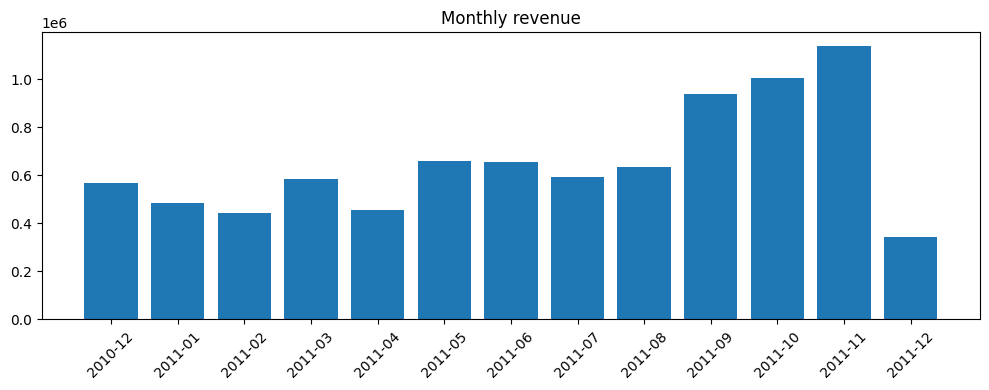

In [9]:
plt.figure(figsize=(10, 4))
plt.bar(monthly["month"], monthly["revenue"])
plt.title("Monthly revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_revenue.png")
plt.show()

Sales go up from September and are highest in November, before Christmas. December 2011 is low only because the data stops on 9 December.

### Month on month growth (using LAG)

In [10]:
pd.read_sql("""
WITH m AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           SUM(Revenue) AS revenue
    FROM sales
    GROUP BY month
)
SELECT month,
       ROUND(revenue) AS revenue,
       ROUND(100 * (revenue - LAG(revenue) OVER (ORDER BY month)) / LAG(revenue) OVER (ORDER BY month), 1) AS growth_pct
FROM m
""", conn)

,month,revenue,growth_pct
0,2010-12,565750.0,NaN
1,2011-01,485699.0,-14.1
2,2011-02,442494.0,-8.9
3,2011-03,583844.0,31.9
4,2011-04,454841.0,-22.1
5,2011-05,659678.0,45.0
6,2011-06,653765.0,-0.9
7,2011-07,592104.0,-9.4
8,2011-08,635864.0,7.4
9,2011-09,939653.0,47.8


### Top 5 countries

In [11]:
pd.read_sql("""
SELECT Country,
       COUNT(DISTINCT CustomerID) AS customers,
       ROUND(SUM(Revenue))        AS revenue
FROM sales
GROUP BY Country
ORDER BY revenue DESC
LIMIT 5
""", conn)

,Country,customers,revenue
0,United Kingdom,3915,6998677.0
1,Netherlands,9,283889.0
2,EIRE,3,261888.0
3,Germany,94,205381.0
4,France,87,183988.0


Most of the revenue comes from the UK.

### Top 5 products

In [12]:
pd.read_sql("""
SELECT Description,
       SUM(Quantity)       AS units,
       ROUND(SUM(Revenue)) AS revenue
FROM sales
GROUP BY Description
ORDER BY revenue DESC
LIMIT 5
""", conn)

,Description,units,revenue
0,REGENCY CAKESTAND 3 TIER,12374,142265.0
1,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.0
2,JUMBO BAG RED RETROSPOT,46078,85041.0
3,PARTY BUNTING,15279,68785.0
4,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.0


### How many customers ordered only once?

In [13]:
pd.read_sql("""
WITH c AS (
    SELECT CustomerID, COUNT(DISTINCT InvoiceNo) AS orders
    FROM sales
    GROUP BY CustomerID
)
SELECT CASE WHEN orders = 1 THEN 'one time' ELSE 'repeat' END AS customer_type,
       COUNT(*) AS customers
FROM c
GROUP BY customer_type
""", conn)

,customer_type,customers
0,one time,1505
1,repeat,2828


## RFM segmentation

RFM means:
- Recency: days since the last order
- Frequency: number of orders
- Monetary: total money spent

I gave every customer a score from 1 to 5 for recency and frequency using NTILE(5), and then put them in 4 groups:
- Champions: bought recently and buy often
- At risk: used to buy often but not recently
- Active: bought recently
- Lost: everyone else

In [14]:
rfm = pd.read_sql("""
WITH c AS (
    SELECT CustomerID,
           CAST(julianday('2011-12-10') - julianday(MAX(InvoiceDate)) AS INT) AS recency,
           COUNT(DISTINCT InvoiceNo) AS frequency,
           SUM(Revenue) AS monetary
    FROM sales
    GROUP BY CustomerID
),
scores AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency DESC) AS r,
           NTILE(5) OVER (ORDER BY frequency)    AS f
    FROM c
)
SELECT *,
       CASE
           WHEN r >= 4 AND f >= 4 THEN 'Champions'
           WHEN r <= 2 AND f >= 3 THEN 'At risk'
           WHEN r >= 3 THEN 'Active'
           ELSE 'Lost'
       END AS segment
FROM scores
""", conn)

rfm.head()

,CustomerID,recency,frequency,monetary,r,f,segment
0,12791,373,1,177.60,1,1,Lost
1,13065,373,1,205.86,1,1,Lost
2,13747,373,1,79.60,1,1,Lost
3,14142,373,1,311.81,1,1,Lost
4,14237,373,1,161.00,1,1,Lost


In [15]:
segments = rfm.groupby("segment").agg(customers=("CustomerID", "count"), revenue=("monetary", "sum"))
segments["customers_%"] = (segments["customers"] / segments["customers"].sum() * 100).round(1)
segments["revenue_%"] = (segments["revenue"] / segments["revenue"].sum() * 100).round(1)
segments.sort_values("revenue", ascending=False)

,customers,revenue,customers_%,revenue_%
segment,,,,
Champions,1123,5788016.541,25.9,68.1
Active,1476,1467288.020,34.1,17.3
At risk,650,802485.501,15.0,9.4
Lost,1084,440470.381,25.0,5.2


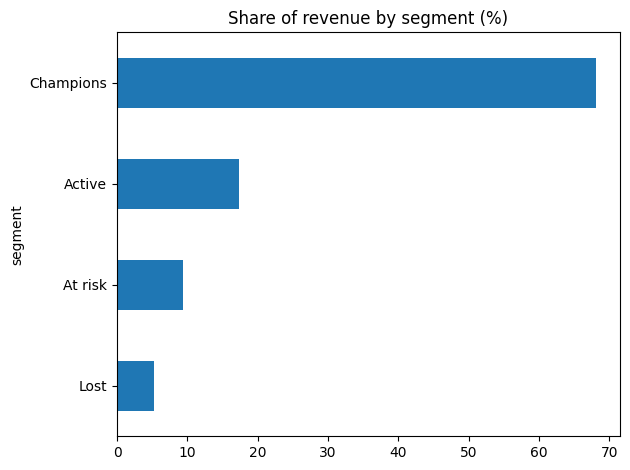

In [16]:
segments["revenue_%"].sort_values().plot(kind="barh", title="Share of revenue by segment (%)")
plt.tight_layout()
plt.savefig("segments.png")
plt.show()

## Conclusion

- Champions are about 26% of customers but bring about 68% of the revenue.
- 650 customers are "At risk". They used to buy often but have not ordered for a long time.
- About 35% of customers ordered only once.
- Sales are highest in October and November.
- The UK brings most of the revenue.

Suggestions for the business:
1. Keep the Champions happy, for example with a loyalty offer.
2. Send a special offer to the At risk customers to bring them back.
3. Follow up with new customers after their first order.
4. Prepare stock early for the Christmas season.

Limitations: the data is only for one shop and one year, there is no cost data so I can't calculate profit, and rows without a customer ID are not included.